# Project 3 (Due November 6): Clustering and Anomaly Detection


This project studies two different kinds of irregularities in financial data: **isolated recording errors** and a **contiguous interval of unusual joint statistical behavior**. You will use DBSCAN for the former and window-based covariance representations with PCA, K-means, and hierarchical clustering for the latter.

Use only `polluteddata.csv`. You may use NumPy, pandas, SciPy, Matplotlib, and scikit-learn. Fix random seeds where appropriate and state your main modeling choices.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

SEED = 4500


## Data

The file contains **1,709 half-hour observations of one asset**, with no header. Using zero-based column numbers, column 0 is the half-hour index $t$, and column $k+1$ contains

$$
x_{t,k}=p(t,k)-p(t,0),\qquad k=0,\ldots,29,
$$

where $p(t,k)$ is the recorded price at minute $k$ within half-hour $t$. These are price differences, **not** percentage returns. Each row therefore includes the half-hour index and 30 intraperiod measurements (the minute-0 price change is zero).

The data contain **exactly six isolated recording errors**, at unknown observations and minutes. Separately, during an unknown **contiguous interval $[t_1,t_2]$**, the data exhibit a significant change in their **joint statistical behavior**, particularly covariance structure. Your goals are to identify the six isolated errors and estimate the anomalous interval.



In [3]:
data = pd.read_csv('polluteddata.csv', header=None)
print('Data shape:', data.shape)
print(data.head(3))


Data shape: (1709, 31)
    0    1     2     3      4     5      6      7      8      9   ...     21  \
0  0.0  0.0 -3.00 -8.26 -10.55 -8.56 -18.08 -12.67 -14.29 -16.08  ... -27.58   
1  1.0  0.0  0.12 -0.41  -2.56  0.15  -1.65  -5.14  -5.09  -8.06  ...  -6.65   
2  2.0  0.0 -2.80 -3.46  -5.80 -3.86  -2.60  -5.30  -4.81  -3.30  ... -12.74   

      22     23     24     25     26     27     28     29     30  
0 -31.51 -27.53 -25.24 -25.32 -24.44 -28.04 -30.94 -29.57 -27.56  
1  -5.43  -6.13  -3.42  -4.48  -4.85  -4.47  -4.68  -2.10  -0.28  
2 -13.02 -15.99 -14.15 -14.92 -16.80 -16.88 -19.53 -25.30 -19.60  

[3 rows x 31 columns]


# Task 1: Data exploration and preprocessing

Inspect the data, check its basic structure and quality, and provide a simple exploratory visualization. Prepare suitable feature representations for the subsequent tasks.

In [4]:
# Task 1: your data exploration and preprocessing


print("Shape:", data.shape)
print("\nData types:")
print(data.dtypes.value_counts())


print("\nMissing values:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Infinite values:", np.isinf(data.to_numpy()).sum())

print("\nSummary statistics:")
display(data.iloc[:, 1:].describe())

Shape: (1709, 31)

Data types:
float64    31
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0
Infinite values: 0

Summary statistics:


,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
count,1709.0,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,...,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000,1709.000000
mean,0.0,0.094744,0.006594,0.066914,0.294528,0.224361,0.313219,-0.004143,0.169033,0.091920,...,-0.273401,0.209558,0.186624,0.278519,0.278602,-0.131089,0.171991,-0.135022,-0.105291,0.291442
std,0.0,3.247338,6.197354,6.034463,5.546020,6.385154,6.846385,10.741715,7.988759,8.606869,...,17.102589,10.611540,10.812969,11.127263,11.527265,14.472260,12.298652,14.325939,15.023754,13.195456
min,0.0,-15.650000,-56.960000,-66.380000,-38.380000,-46.020000,-46.740000,-64.360000,-47.880000,-51.720000,...,-96.827911,-68.190000,-72.410000,-78.670000,-70.880000,-75.600000,-74.070000,-71.777607,-78.234077,-64.820000
25%,0.0,-1.100000,-1.779856,-2.260000,-2.230000,-2.750000,-2.990000,-3.540000,-3.740000,-4.160000,...,-6.090000,-5.480000,-5.420000,-5.420364,-5.720000,-6.610000,-5.980000,-6.950000,-7.220000,-6.600000
50%,0.0,-0.010000,0.070000,0.040000,0.060000,0.080000,0.050000,0.100000,0.040000,0.060000,...,-0.200000,-0.130000,-0.340000,-0.080000,-0.140000,-0.230000,-0.230000,-0.490000,-0.310000,-0.070000
75%,0.0,1.188527,1.860000,2.290000,2.392062,2.890000,3.200000,3.520000,3.460000,3.520000,...,5.880000,5.300000,5.270000,5.370000,5.530000,5.770000,5.630000,5.980000,6.290000,6.540000
max,0.0,60.380000,67.930000,64.060000,68.040000,76.880000,83.300000,78.830000,84.440000,79.840000,...,87.569365,88.050000,88.300000,92.190000,96.050000,100.080000,101.070000,94.510000,98.690000,101.570000


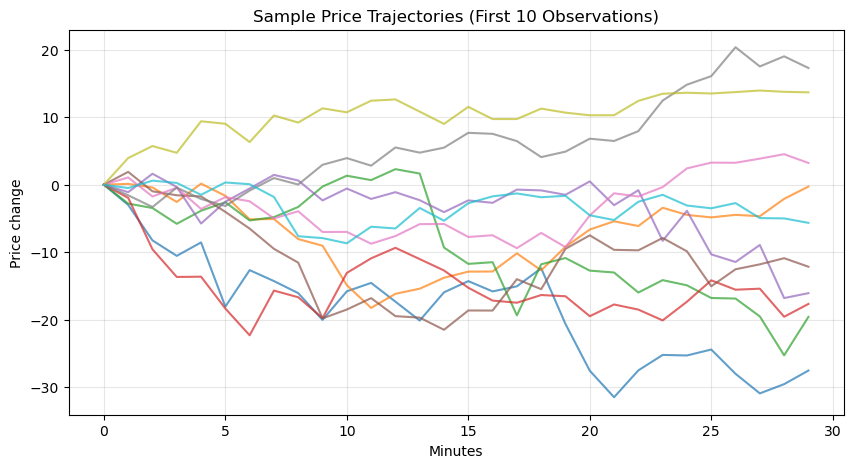

In [5]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.plot(range(30), data.iloc[i, 1:], alpha=0.7)

plt.xlabel("Minutes")
plt.ylabel("Price change")
plt.title("Sample Price Trajectories (First 10 Observations)")
plt.grid(alpha=0.3)
plt.show()


From the above graph, we can see that the sampled price trajectorie all begin at 0 at time 0 and diverge from there. The spread in behavior increases over time, and further analysis is required to understand this.

In [6]:
time_idx = data.iloc[:, 0].to_numpy()
X = data.iloc[:, 1:].to_numpy()

# minute-to-minute price changes
X_diff = np.diff(X, axis=1)

print("Original features:", X.shape)
print("Minute-to-minute changes:", X_diff.shape)

Original features: (1709, 30)
Minute-to-minute changes: (1709, 29)


In [7]:
from sklearn.preprocessing import StandardScaler

X_features = X[:, 1:]

# standardize feature representations
X_scaled = StandardScaler().fit_transform(X_features)
X_diff_scaled = StandardScaler().fit_transform(X_diff)

print("Scaled price changes:", X_scaled.shape)
print("Scaled minute-to-minute changes:", X_diff_scaled.shape)


Scaled price changes: (1709, 29)
Scaled minute-to-minute changes: (1709, 29)


The dataset has 1709 observations and 30 price measurements per observation. There are no missing or duplicate rows. In the graph, we saw that the price may fluctuate either up or down, and the spread generally increased with time over the 30 minute dataset given. For preprocessing, minute 0 was removed and time indices were separated from price measurements. We also calculated the minute by minute changes of the price so that we can see more specific changes rather than just the cumulative movement. We also created a standardized version of both feature representations (for distance-based clustering). The original dataset was retained and no observations were removed.

# Task 2: DBSCAN — isolated recording errors

Apply DBSCAN to identify the **six isolated recording errors**.

1. Choose a representation of each half-hour observation and an appropriate distance metric. Briefly justify your choices.
2. Select `eps` and `min_samples`, using a neighborhood-distance diagnostic or another systematic parameter-selection approach. You **may use the known number of recording errors (six)** to guide your selection, but should not assume that six noise labels guarantee six correct detections.
3. Report the candidate error half-hour indices, the number of DBSCAN clusters, and the noise count.
4. Examine whether your results remain reasonably stable for nearby parameter choices, and discuss possible false positives or missed errors.

Do not assume that DBSCAN noise observations must coincide with the contiguous anomalous interval.

In [17]:
# Task 2: your DBSCAN implementation and analysis

A *window* in Tasks 3–4 consists of consecutive **half-hour observations (rows)**, not consecutive minutes within a half-hour. Cluster labels are arbitrary; a cluster or noise label alone does not prove that an observation is anomalous.

# Task 3: Window-based covariance analysis, PCA, and K-means

The main objective is to identify the **contiguous interval** with unusual joint statistical behavior. Instead of clustering individual half-hours, study how the data's covariance structure evolves across **windows of consecutive half-hours**.

1. Construct an informative window-level representation of covariance behavior. Choose and briefly motivate the windowing and feature-design choices.
2. Use **PCA and K-means** to investigate patterns across windows. Select reasonable settings and interpret the resulting groups.
3. Provide visualizations that connect the window-level results back to time and indicate any unusual statistical regime.
4. Report an estimated interval $[\hat t_1,\hat t_2]$ and explain how you infer its boundaries from your results. Discuss any important uncertainty introduced by the window construction.

You have flexibility in feature construction and parameter selection; justify your design rather than following a prescribed recipe.

### Discussion 1:
It is unclear whether using the orignal data of cumulative price changes in the half hour window or the difference version that capture the minute-level change would yield a better performance in coveriance behavior analysis.

**1)** The original data record a cumulative time-series behavior, any two time points are naturally correlated, the covariance matrix have more significance in off-diagonal values, the transition in covariance structure across windows could be reflected by off-diagonal values, so the variance features would not be the sole driver, there is likely more PCs having large explanatory power to be considered for K-means.

**2)** The differenced data smoothed out some joint behaviour of prices, the off-diagonal values are usually small, yielding a nearly diagonal matrix, cross-window value change of off-diagonal values are largely random noise. However, the minute level change could be more obvious, and likely PC1 could account for more variability.

The primary focus would be still on **the original data**, since large PC1 explainabiltiy is not necessarily a good thing, dominance of variance and PC1 would create very limited information for K-means, with only one dimension of feature for clustering, the result may not be robust across changes in parameter

The size of rolling window is initially set at $h=50$, with rolling stepsize of $d=1$ for more accurate approximation,each window therefore has dimension $h\times 29$, the covariance matrix is computed within each normal (without standardization of price changes since changing of absolute variance itself could be indicator of unusual joint statistical behavior. Across the each window the $29\times 29$ covariance matrix is taken upper right triangle and flattened into a $1\times 435$ feature matrix. The whole data set is therefore of dimension $1660\times 435$. The features capture the minute level covariance changes within each window. 

Two sets of standardization is conducted, not to completely wipe out the variance change across window, but to reduce its influence in PCA (since diagonal values of the covariance matrix is naturally larger in  magnitude, we need to avoid PCA being driven by mostly their variation), so cross window standardizaiton for each one out of the 435 features is conducted, to make them comparable with each other. The PC-score is also standardized across the windows, to aviod PC1's dominance in clustering given its large variance.

### Discussion 2:
For high dimension feature space, retaining PCs involves tradeoff between explainability of variability and too much noise introduced. But given this "time series data" on the same asset, multicollinearity is expected, the first PC already accounts for 66% of variation, and first 2 PC explain 90%. 

The initial number of PC retained is set at $p=2$, to at least have more dimensions to consider when performing K-means. The Elbow plot is displayed, the turning point is around $k=3$,so the initial choice of number of clusters is set at $k=2$ (distinct ususual vs unusual class) with $k=3,4,5$ checked subsequently for robustness of results. 

Large number of clusters is proven to be very conservative, creating unnecessary seperations, but there is still a consecutive interval of window $731-928$ segmented from the rest of the group. K-means clustering is conducted on the scores matrix $1660\times p$. 

In [8]:
# Task 3: your window features, PCA, K-means, and interval estimate
# Definition of parameters
h=50 # Window size (rows)
d=1 # rolling stepsize (row)
# p: number of features retained
p=2
# k in K-means to be selected with Elbow method
# Loading data
print(data.shape)
data_copy=data.iloc[:,1:]
data_new=np.diff(data_copy,axis=1)
df=pd.DataFrame(data.iloc[:,2:],index=data[0])
print(df.head())

(1709, 31)
       2     3      4      5      6      7      8      9      10     11  ...  \
0                                                                        ...   
0.0 -3.00 -8.26 -10.55  -8.56 -18.08 -12.67 -14.29 -16.08 -20.04 -15.81  ...   
1.0  0.12 -0.41  -2.56   0.15  -1.65  -5.14  -5.09  -8.06  -9.05 -14.90  ...   
2.0 -2.80 -3.46  -5.80  -3.86  -2.60  -5.30  -4.81  -3.30  -0.28   1.33  ...   
3.0 -1.95 -9.58 -13.68 -13.64 -18.36 -22.33 -15.70 -16.69 -19.78 -13.08  ...   
4.0 -1.11  1.62  -0.34  -5.76  -2.53  -0.56   1.45   0.62  -2.33  -0.57  ...   

        21     22     23     24     25     26     27     28     29     30  
0                                                                          
0.0 -27.58 -31.51 -27.53 -25.24 -25.32 -24.44 -28.04 -30.94 -29.57 -27.56  
1.0  -6.65  -5.43  -6.13  -3.42  -4.48  -4.85  -4.47  -4.68  -2.10  -0.28  
2.0 -12.74 -13.02 -15.99 -14.15 -14.92 -16.80 -16.88 -19.53 -25.30 -19.60  
3.0 -19.50 -17.76 -18.52 -20.12 -17.35 -14.18 -1

(1660, 50, 29)


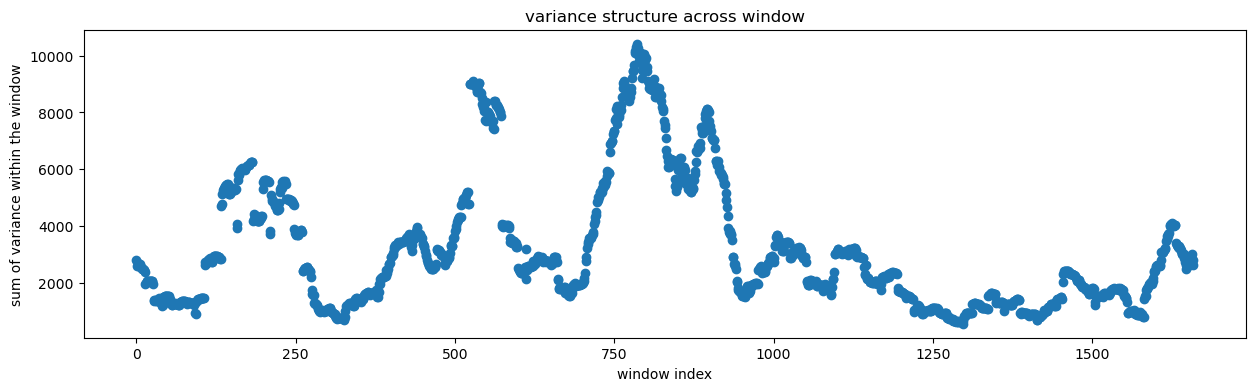

(1660, 435)
PC1 top features: [257 218 275 238 197]
PC2 top features: [170 172 180 177 235]
257 of PC1 top loadings is off-diagonal
218 of PC1 top loadings is off-diagonal
275 of PC1 top loadings is off-diagonal
238 of PC1 top loadings is off-diagonal
197 of PC1 top loadings is off-diagonal
170 of PC2 top loadings is off-diagonal
172 of PC2 top loadings is off-diagonal
180 of PC2 top loadings is off-diagonal
177 of PC2 top loadings is off-diagonal
235 of PC2 top loadings is off-diagonal
Explained variation at p=2 is 0.9032992434863317


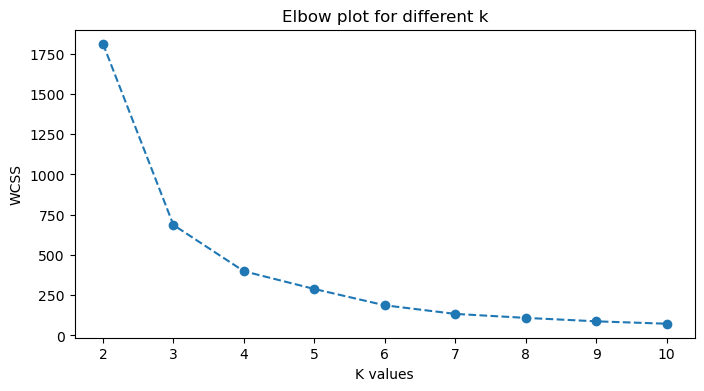

In [9]:
# Below is the implementation with the flattened upper right triangle covariance matrix from each window as features
# function for rolling window construction, computing window level features (29x29->1x435)
# compelling window level features across all windows (# of total windows x 435)
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

def window_cov(df,h,d,m):# m as the number of subintervals in the row, eg minute-level:m=30, the later analysis of 5min level data m=6
    # sliding window view (1660,29,50)
    windows=sliding_window_view(df,window_shape=h,axis=0)
    # slicing for stepsize=d 
    windows=windows[::d]
    # transpose to get (1660,50,29)
    windows=windows.transpose(0,2,1)
    print(windows.shape)
    # Covariance matrix across all windows (1660,29,29)
    centered=windows-np.mean(windows,axis=1,keepdims=True)
    cov_matrices=np.matmul(centered.transpose(0,2,1),centered)/(h-1)
    # plot the trace to check the variance structure
    trace_w = np.trace(cov_matrices, axis1=1, axis2=2) 
    plt.figure(figsize=(15, 4))
    plt.scatter(np.arange(0,windows.shape[0],1),trace_w)
    plt.xlabel('window index')
    plt.ylabel('sum of variance within the window')
    plt.title('variance structure across window')
    plt.show()
    # Taking the upper left triangle and flatten (1660,435)
    features=cov_matrices[:,np.triu_indices(m-1)[0],np.triu_indices(m-1)[1]]
    # Standardize each feature across window
    scaler=StandardScaler()
    features=scaler.fit_transform(features)
    print(features.shape)
    return features
    
# function of PCA across the covariance matrix (435x435), checking for features retains, obtaining score (# number of windows x p)
def PCA_km(features):
    pca=PCA(n_components=p,random_state=SEED)
    score=pca.fit_transform(features)
    loadings = pca.components_  # (p, 435)
    # Check the top five largest PC loadings'index in the flatten feature space
    pc1_tpload=np.argsort(np.abs(loadings[0]))[-5:]
    pc2_tpload=np.argsort(np.abs(loadings[1]))[-5:]
    print("PC1 top features:", pc1_tpload)
    print("PC2 top features:", pc2_tpload)
    # Check whehter they are off diagonal in the original cov matrix
    rows,cols=np.triu_indices(29)
    for idx in pc1_tpload:
        result=f'{idx} of PC1 top loadings is off-diagonal' if rows[idx]!=cols[idx] else f'{idx} of PC1 top loadings is on the diagonal'
        print(result)
    for idx in pc2_tpload:
        result=f'{idx} of PC2 top loadings is off-diagonal' if rows[idx]!=cols[idx] else f'{idx} of PC2 top loadings is on the diagonal'
        print(result)
    # standardize the score across the p PCs
    scaler=StandardScaler()
    score=scaler.fit_transform(score[:,:p])
    print(f'Explained variation at p={p} is {sum(pca.explained_variance_ratio_)}')
    return score 
    
# function of K-means across score matrix, under a given list of k
def k_means(score,lst_k):
    lst_inertia=[]
    for k in lst_k:
        kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
        kmeans.fit(score)
        lst_inertia.append(kmeans.inertia_)
    plt.figure(figsize=(8,4))
    plt.plot(lst_k,lst_inertia,marker='o',linestyle='--')
    plt.title('Elbow plot for different k')
    plt.xlabel('K values')
    plt.ylabel('WCSS')
    plt.show()
    return

# Main function of defining list of K variables, calling K-means function to check WCSS and select a k for final evaluation
lst_k=np.arange(2,11,1)
features=window_cov(df,h,d,30)
score=PCA_km(features)
k_means(score,lst_k)

In [10]:
k=2
kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
labels=kmeans.fit_predict(score)
features_groups=pd.DataFrame({
    'Window idx':np.arange(0,features.shape[0],1),
    'Cluster':labels+1})
for i,group in features_groups.groupby('Cluster'):
    print(f'Cluster {i} ({len(group)} intervals):{group.index}')

Cluster 1 (1462 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1462)
Cluster 2 (198 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       919, 920, 921, 922, 923, 924, 925, 926, 927, 928],
      dtype='int64', length=198)


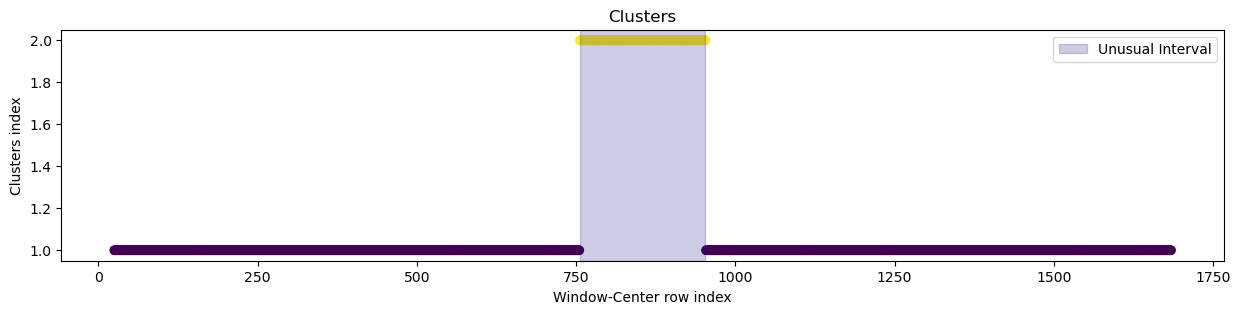

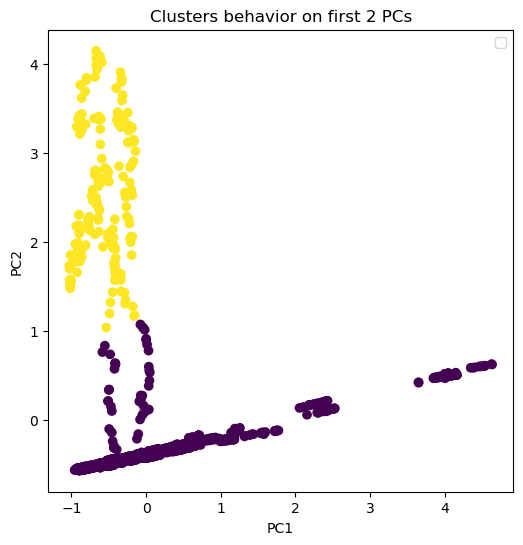

In [11]:
# Function for visualization linking back to time interval
def visualization(features_groups,h,d,start,end):#start and end of the abnormal interval
    # clusters displayed on the original timeline,with each window indexed with center-row (1709)
    orig_idx=np.arange(features_groups.shape[0])+h//2
    plt.figure(figsize=(15,3))
    plt.scatter(orig_idx,features_groups['Cluster'],c=features_groups['Cluster'])
    plt.axvspan(start+h//2,end+h//2,color='navy',alpha=0.2,label='Unusual Interval')
    plt.title('Clusters')
    plt.xlabel('Window-Center row index')
    plt.ylabel('Clusters index')
    plt.legend()
    plt.show()
    # Clustering on PC1 and PC2
    plt.figure(figsize=(6,6))
    plt.scatter(score[:,0],score[:,1],c=features_groups['Cluster'])
    #plt.scatter(score[:,0],np.ones(len(score[:,0])),c=features_groups['Cluster'])
    plt.title('Clusters behavior on first 2 PCs')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.legend()
    plt.show()

visualization(features_groups,h,d,731,928)

### Discussion 3:

Creating the plots above,it is clear that a period of consecutive windows is segmented to a seperate cluster due to different statistical behavior. the window index is translated back to the center row of the window, so the corresponding **center row** of the unusual interval is around $756-952$ as demonstrated above, which means under $h=50$, the unusual window is spanning across the $731th$ to $977th$ half-hour row, however there is error in approximation due to window size, it is hard to tell which specific rows marks the transition of two 'regimes.

Studying the different behavior of clusters on the first 2 PCs, the unusual interval has a larger absolute value for PC2. The usual period has PC2 smaller in absolute value term, variation concentrated across PC1, displaying rather consistent changes in value. PC1 could be intepreted as the common structural flucuations in volatility due to regular trend flows, while PC2 is more of the sudden change of covariance pattern that concentrated in a specific period.

From studying in the largest loadings index of PC1 and PC2, they are all off-diagonal covariance, therefore, the driver of unusual regime shift is primarily the change in covariance of two different minutes across windows, instead of sudden shift in volatility of particular minute. 


------------------Results with k=3,window size =30------------------------
Cluster 1 (1347 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1347)
Cluster 2 (116 intervals):Index([133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       ...
       563, 564, 565, 566, 567, 568, 569, 570, 571, 572],
      dtype='int64', length=116)
Cluster 3 (197 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       918, 919, 920, 921, 922, 923, 924, 925, 926, 927],
      dtype='int64', length=197)

------------------Results with k=3,window size =100------------------------
Cluster 1 (1347 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1347)
Cluster 2 (116 intervals):Index([133, 134, 135, 136, 137, 138, 

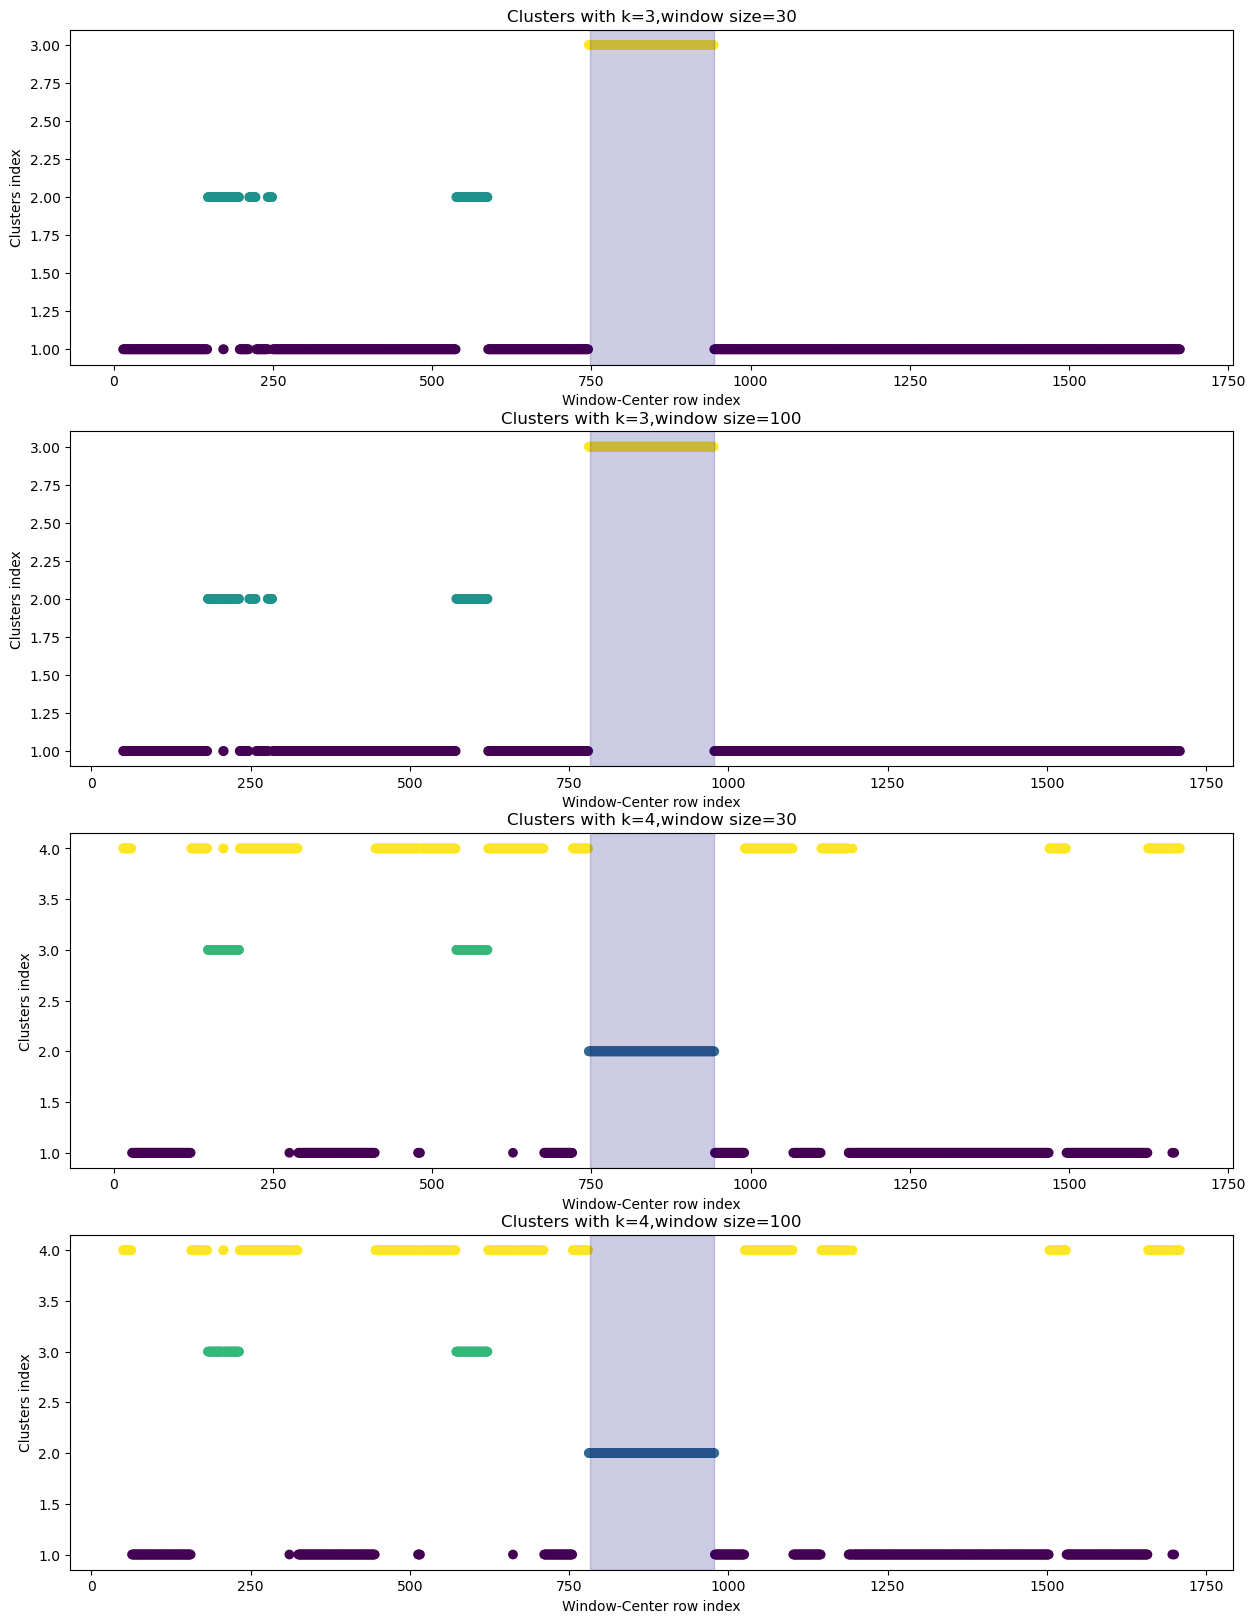

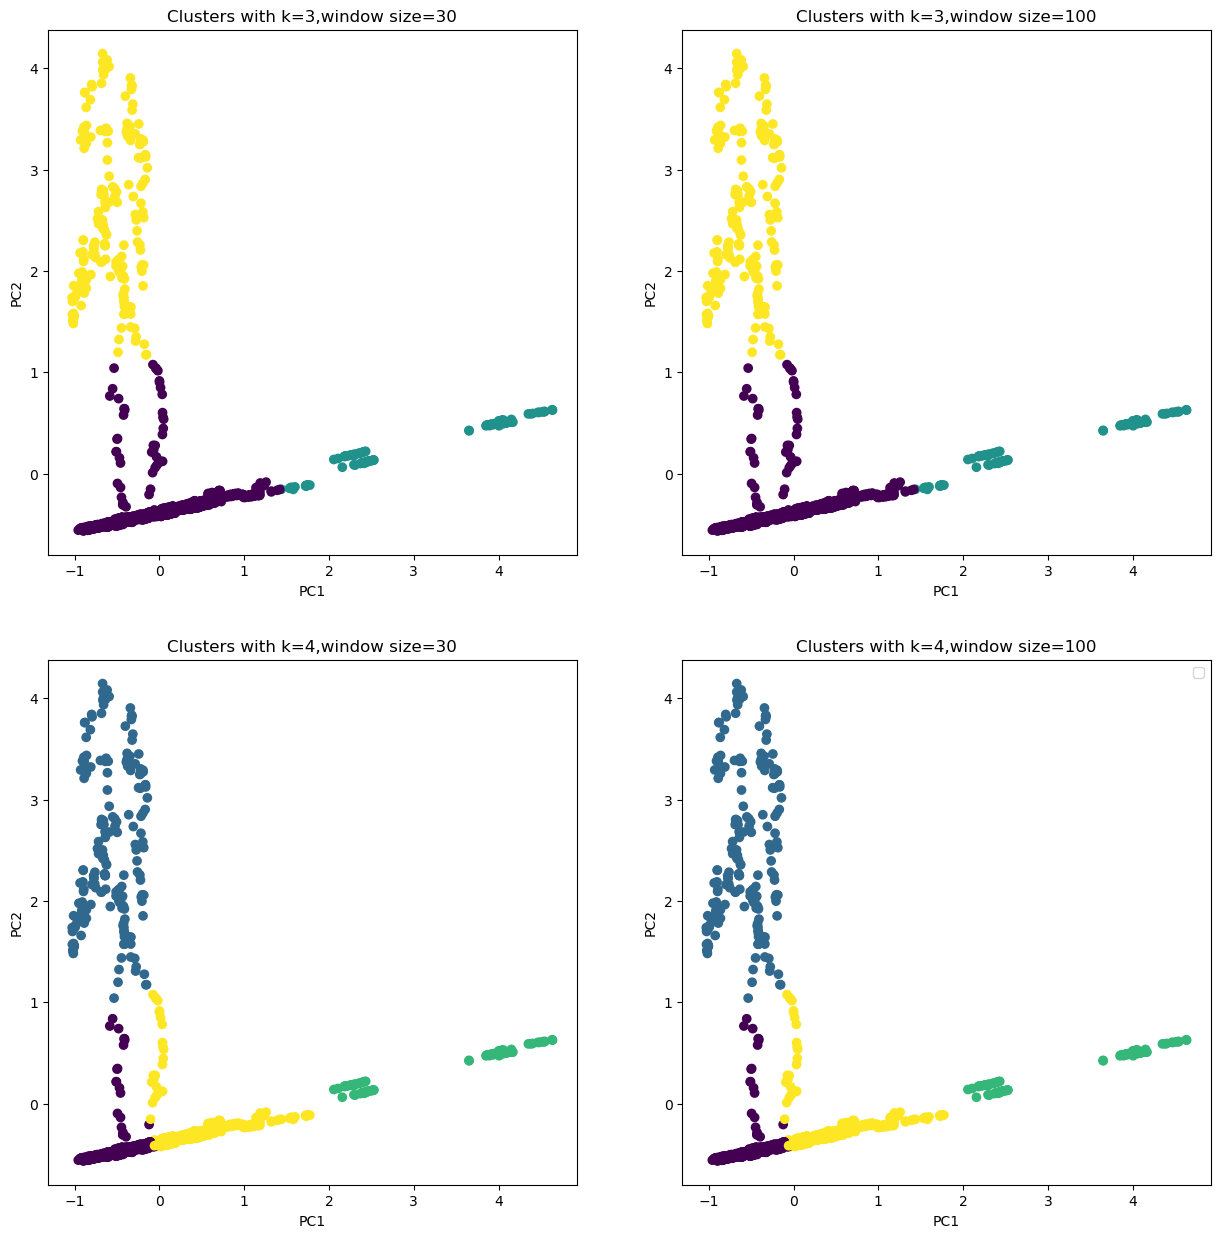

In [12]:
# Some robustness check across different values of h and k
from matplotlib.pyplot import subplots
fig,axes=plt.subplots(4,1,figsize=(15,20))
axes=axes.flatten()
axes_pc=plt.subplots(2,2,figsize=(15,15))[1]
axes_pc=axes_pc.flatten()
idx=0
for k in range(3,5):
    for h in [30,100]:
        kmeans=KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=10,
                    max_iter=300,
                    tol=1e-4,
                    random_state=SEED)
        labels=kmeans.fit_predict(score)
        features_groups=pd.DataFrame({
            'Window idx':np.arange(0,features.shape[0],1),
            'Cluster':labels+1})
        print(f'\n------------------Results with k={k},window size ={h}------------------------')
        for i,group in features_groups.groupby('Cluster'):
            print(f'Cluster {i} ({len(group)} intervals):{group.index}')
        # plot
        orig_idx=np.arange(features_groups.shape[0])+h//2
        axes[idx].scatter(orig_idx,features_groups['Cluster'],c=features_groups['Cluster'])
        axes[idx].axvspan(733+h//2,927+h//2,color='navy',alpha=0.2,label='Unusual Interval')
        axes[idx].set_title(f'Clusters with k={k},window size={h}')
        axes[idx].set_xlabel('Window-Center row index')
        axes[idx].set_ylabel('Clusters index')
        axes_pc[idx].scatter(score[:,0],score[:,1],c=features_groups['Cluster'])
        axes_pc[idx].set_title(f'Clusters with k={k},window size={h}')
        axes_pc[idx].set_xlabel('PC1')
        axes_pc[idx].set_ylabel('PC2')
        idx+=1
plt.legend()
plt.show()

### Discussion 4:
The main unsuual regime is around the center rows of the indexed window $731$ and $928$, these window indices are equivalently the index of the first row in corresponding window. It is worth noting that changing of window size alone across $30$, $50$, and $100$ does not change the unusual clusters' window index, while changing k some times have window $928$ clustered as 'usual', which is intuitive since at the boundary of unusual regime, the mixuture of rows constructing the window will overall the result is robust across different parameter values.

Under $h=50$, the anomalous regime took place from around $731th$ to $976th$ half hour which is the from the first row of window 733 to the last row: $928+50-1=977$ of window 928, with the core regime shift centered aorund $758$ to $952$ (center rows of the two windows).

Uncertainty occurs due to the blurred effects around the boundaries.Because each window contains 50 consecutive half-hour observations, a window is labeled "anomalous" as long as a significant portion of its 50 rows included the true anomaly data, and we do not know when its 'contamination' effect on a particular window starts to be significant enough to be captured.

## A trial with differenced data to check robustness of results

(1660, 50, 29)


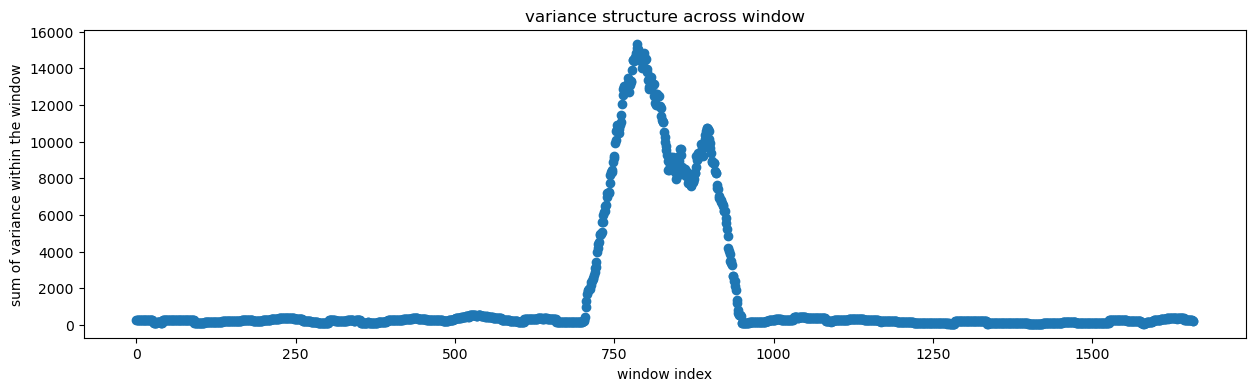

(1660, 435)
PC1 top features: [325 395 320 321 394]
PC2 top features: [ 15 206 204   0 245]
325 of PC1 top loadings is off-diagonal
395 of PC1 top loadings is off-diagonal
320 of PC1 top loadings is off-diagonal
321 of PC1 top loadings is off-diagonal
394 of PC1 top loadings is off-diagonal
15 of PC2 top loadings is off-diagonal
206 of PC2 top loadings is off-diagonal
204 of PC2 top loadings is on the diagonal
0 of PC2 top loadings is on the diagonal
245 of PC2 top loadings is on the diagonal
Explained variation at p=2 is 0.9461664009807624


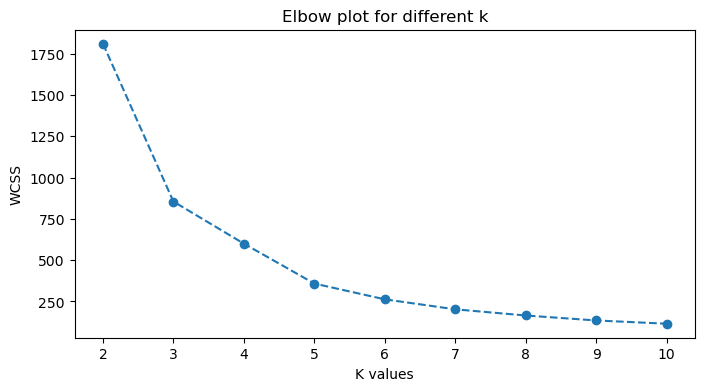

In [13]:
# Check the result with differenced series
p=2
h=50
features=window_cov(X_diff,h,d,30)
score=PCA_km(features)
k_means(score,lst_k)

In [14]:
k=3
kmeans=KMeans(
            n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=SEED)
labels=kmeans.fit_predict(score)
features_groups=pd.DataFrame({
    'Window idx':np.arange(0,features.shape[0],1),
    'Cluster':labels+1})
for i,group in features_groups.groupby('Cluster'):
    print(f'Cluster {i} ({len(group)} intervals):{group.index}')

Cluster 1 (1401 intervals):Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       1650, 1651, 1652, 1653, 1654, 1655, 1656, 1657, 1658, 1659],
      dtype='int64', length=1401)
Cluster 2 (196 intervals):Index([731, 732, 733, 734, 735, 736, 737, 738, 739, 740,
       ...
       917, 918, 919, 920, 921, 922, 923, 924, 925, 926],
      dtype='int64', length=196)
Cluster 3 (63 intervals):Index([510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522, 523,
       524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537,
       538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548, 549, 550, 551,
       552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565,
       566, 567, 568, 569, 570, 571, 572],
      dtype='int64')


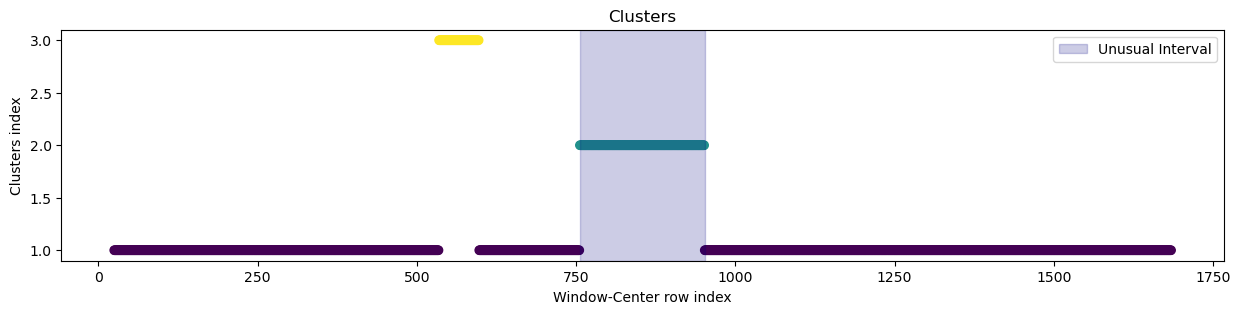

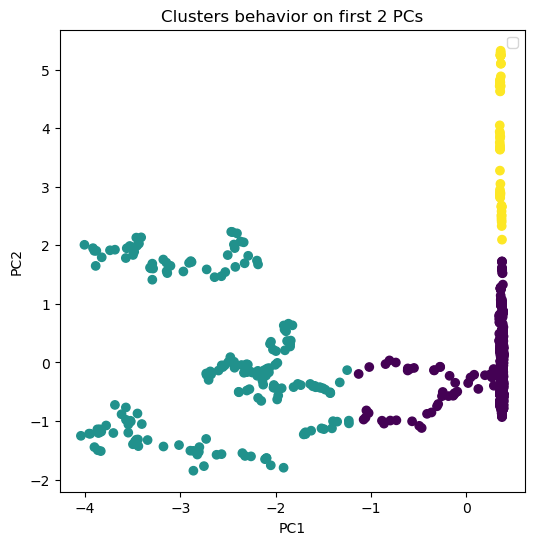

In [15]:
visualization(features_groups,h,d,731,928)

With the differenced data, the trace of window covariance matrices are displayed above, differencing smooth out the volatility in usual regim, but abnormal interval's sudden spike in changes is magnified through squaring, which is evident throgh the plot. PC1 therefore have huge explanatory power of variation, capturing the spike in absolute variance. The clustering however, yielding around the same result, thanks to the standardization of score.

# Task 4: Hierarchical clustering with temporal connectivity

Use a **window-level representation** from Task 3 to investigate time-series segmentation with **Ward hierarchical clustering and temporal connectivity constraints**.

1. Apply Ward clustering with a connectivity graph that links neighboring windows in chronological order. Select a reasonable number of segments.
2. Visualize the clustering labels over time and summarize the resulting contiguous segments and their boundaries.
3. Compare the segmentation and candidate change points with your K-means analysis in Task 3. Does it support a similar anomalous interval? Discuss important differences and limitations.

Remember that a segment boundary is a **candidate change point**, not automatically evidence of anomalous behavior.

In [19]:
# Task 4: your connectivity-constrained Ward clustering

# Task 5: Comparison and conclusion

Summarize the main findings from **DBSCAN, window covariance + PCA + K-means, and connectivity-constrained Ward**. Explain which approach is suited to isolated errors and which to an anomalous interval in the covariance structure.

Report your final six candidate recording-error observations and your best estimate of $[t_1,t_2]$, with brief evidence and limitations.

In [20]:
# Task 5: your comparison and final conclusions